# Segmentação de clientes: RFM, clusterização e o que fazer com quem compra uma vez só

**Pergunta de negócio:** o time de CRM quer segmentar a base para personalizar campanhas. Quais grupos existem, quanto cada um vale e onde vale a pena investir?

**Dados:** cerca de 96 mil pedidos entregues de 93 mil clientes da Olist, de 2017 a 2018 ([Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0). A tabela de pedidos é gerada por `preparar_dados.py`.

**Roteiro**
1. O fato que muda tudo: quase ninguém volta
2. RFM clássico e por que a frequência não ajuda aqui
3. Clusterização por comportamento de compra (K-means), com escolha de k e teste de estabilidade
4. Quem volta? Recompra por segmento e por categoria, com intervalo de confiança
5. Dá para prever quem volta?
6. Recomendações e limitações

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import adjusted_rand_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "..")  # estilo compartilhado do repositório
from comum.estilo import COR, SEQ, aplicar, br, fonte, subtitulo
from segmentacao import (CATEGORIA_PT, JANELA_RECOMPRA, VARIAVEIS, carregar_pedidos, nomear_clusters,
                         primeira_compra, recompra_por_coorte, segmentos_rfm, tabela_clientes, taxa_wilson)

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: Olist Brazilian E-Commerce Public Dataset · elaboração: Cézar Bento"

pedidos = carregar_pedidos()
clientes = tabela_clientes(pedidos)
print(f"{br(len(pedidos))} pedidos entregues · {br(len(clientes))} clientes · "
      f"{pedidos.data.min():%d/%m/%Y} a {pedidos.data.max():%d/%m/%Y}")

96.477 pedidos entregues · 93.357 clientes · 03/10/2016 a 29/08/2018


## 1. O fato que muda tudo: quase ninguém volta

A frequência conta **dias distintos de compra**: dois pedidos no mesmo dia costumam ser um carrinho dividido, não um cliente que voltou.

1 compra     97.84
2 compras     2.00
3 ou mais     0.16


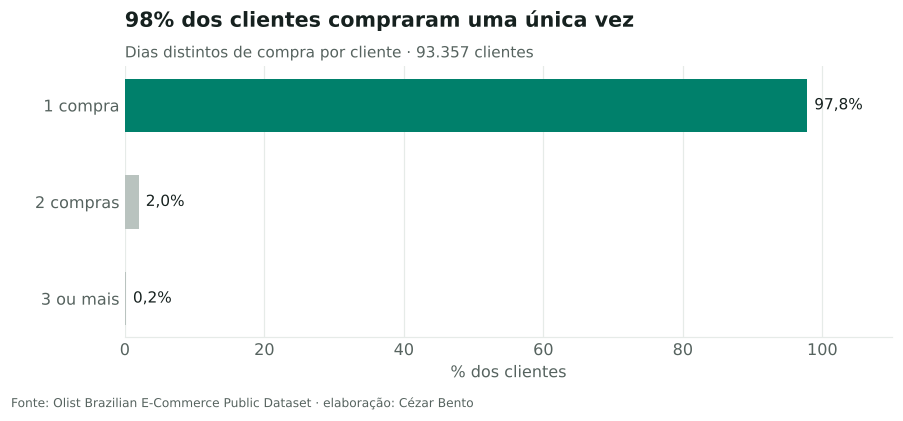

In [2]:
freq = clientes.frequencia.clip(upper=3).value_counts(normalize=True).sort_index()
rotulos = ["1 compra", "2 compras", "3 ou mais"]
print(pd.Series(freq.values * 100, index=rotulos).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 3.2))
cores = [COR["principal"], COR["contexto"], COR["contexto"]]
ax.barh(rotulos[::-1], freq.values[::-1] * 100, color=cores[::-1], height=0.55)
for i, v in enumerate(freq.values[::-1]):
    ax.text(v * 100 + 1, i, f"{br(v * 100, 1)}%", va="center", fontsize=10, color=COR["texto"])
ax.set_xlim(0, 110); ax.grid(axis="y", visible=False); ax.set_xlabel("% dos clientes")
ax.set_title(f"{br(freq.iloc[0] * 100)}% dos clientes compraram uma única vez")
subtitulo(ax, f"Dias distintos de compra por cliente · {br(len(clientes))} clientes")
fonte(fig, FONTE, y=-0.06)
fig.savefig("figuras/01_frequencia.png")

           1    2    3    4    5    6
2017-01  0.6  0.8  1.0  1.4  1.5  2.0
2017-02  0.6  0.9  1.0  1.5  1.6  1.8
2017-03  0.6  1.0  1.4  1.7  1.8  2.0
2017-04  0.9  1.2  1.3  1.6  1.9  2.2
2017-05  1.0  1.5  1.7  2.0  2.2  2.5
2017-06  0.9  1.2  1.6  1.8  2.1  2.4
2017-07  0.9  1.2  1.4  1.7  1.9  2.2
2017-08  1.0  1.3  1.6  1.9  2.3  2.6
2017-09  1.2  1.7  1.9  2.3  2.5  2.6
2017-10  1.0  1.2  1.3  1.5  1.7  1.9
2017-11  0.9  1.2  1.4  1.5  1.7  1.8
2017-12  0.5  0.8  1.1  1.4  1.6  1.7
2018-01  0.7  1.1  1.3  1.6  1.7  1.9
2018-02  0.7  1.1  1.4  1.6  1.8  2.0
2018-03  0.7  1.0  1.3  1.4  1.5  NaN
2018-04  1.0  1.3  1.5  1.6  NaN  NaN
2018-05  1.0  1.2  1.4  NaN  NaN  NaN
2018-06  0.7  0.9  NaN  NaN  NaN  NaN
2018-07  0.9  NaN  NaN  NaN  NaN  NaN


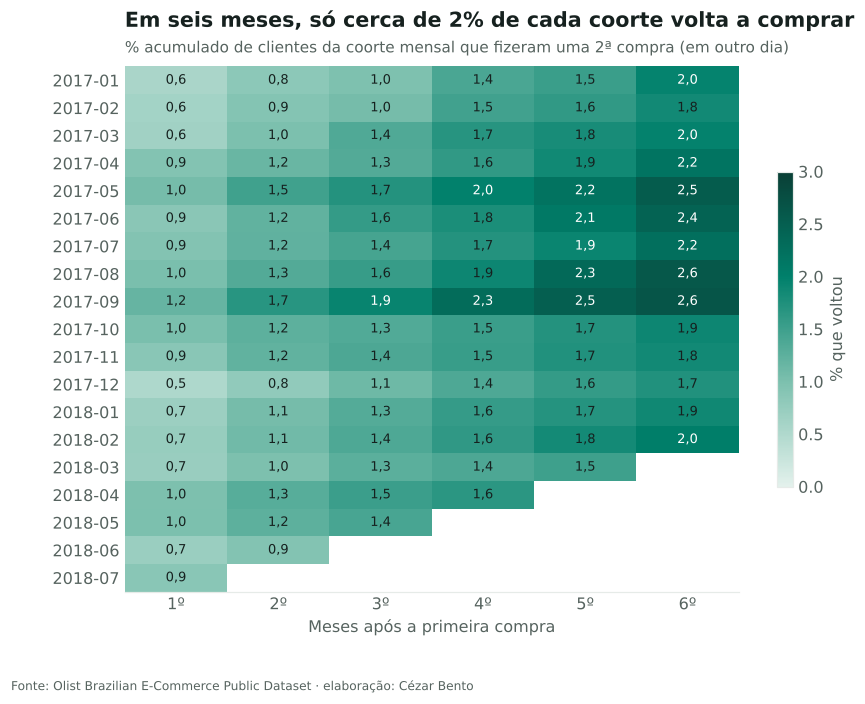

In [3]:
coortes = recompra_por_coorte(pedidos).dropna(how="all")
print((coortes * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 6.2))
im = ax.imshow(coortes.values * 100, cmap=SEQ, aspect="auto", vmin=0, vmax=3)
for (i, j), v in np.ndenumerate(coortes.values):
    if not np.isnan(v):
        ax.text(j, i, br(v * 100, 1), ha="center", va="center", fontsize=8.5,
                color="white" if v * 100 > 1.9 else COR["texto"])
ax.set_xticks(range(coortes.shape[1]), [f"{k}º" for k in coortes.columns])
ax.set_yticks(range(len(coortes)), coortes.index)
ax.grid(False); ax.set_xlabel("Meses após a primeira compra")
ax.set_title("Em seis meses, só cerca de 2% de cada coorte volta a comprar")
subtitulo(ax, "% acumulado de clientes da coorte mensal que fizeram uma 2ª compra (em outro dia)")
fig.colorbar(im, ax=ax, shrink=0.6, label="% que voltou")
fonte(fig, FONTE)
fig.savefig("figuras/02_coortes.png")

**Leitura:** a Olist é, na prática, um negócio de **primeira compra**. Isso não é falha da análise: é a característica mais importante da base, e muda a pergunta do CRM. Segmentar para "fidelizar" tem pouco espaço; segmentar para **entender a primeira compra** (quanto vale, quanto custa entregar, se o cliente ficou satisfeito) tem muito.

## 2. RFM clássico

RFM classifica clientes por **R**ecência (dias desde a última compra), **F**requência e **V**alor monetário. Com 98% dos clientes em F = 1, a frequência vira um corte binário (1 compra × 2 ou mais), e o resto da base é dividido por quintis de recência e valor.

                          clientes    receita  ticket  recencia  % clientes  % receita
segmento_rfm                                                                          
Recorrentes                   2015   646454.2   115.1     168.0         2.2        4.2
Alto valor, recentes         14508  4390388.6   203.9      94.0        15.5       28.5
Alto valor, adormecidos      14081  4343690.0   208.6     382.0        15.1       28.2
Baixo valor, recentes        21772  1588750.0    69.6      93.0        23.3       10.3
Baixo valor, adormecidos     40981  4453179.0    78.6     280.0        43.9       28.9


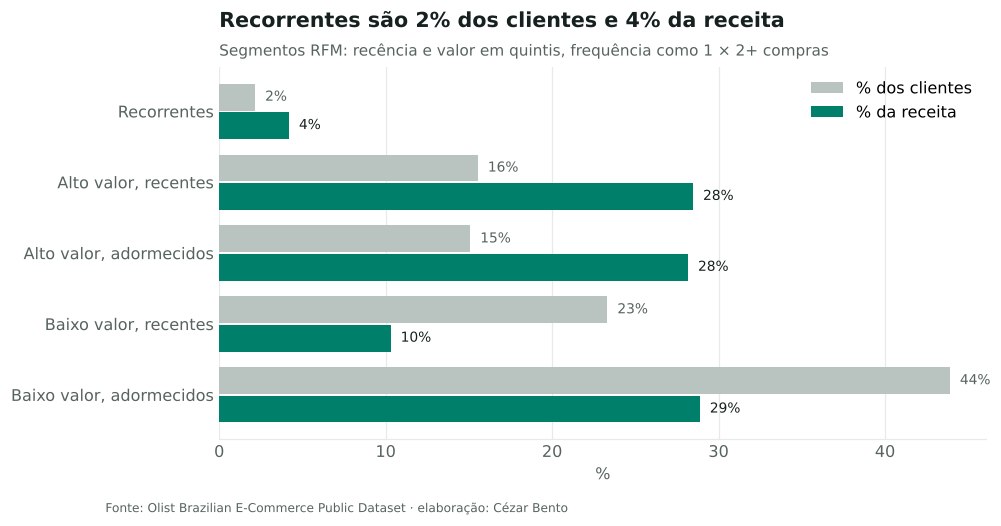

In [4]:
clientes["segmento_rfm"] = segmentos_rfm(clientes)
rfm = clientes.groupby("segmento_rfm").agg(clientes=("valor", "size"), receita=("valor", "sum"),
                                           ticket=("ticket", "median"), recencia=("recencia", "median"))
rfm["% clientes"] = rfm.clientes / rfm.clientes.sum() * 100
rfm["% receita"] = rfm.receita / rfm.receita.sum() * 100
ordem = ["Recorrentes", "Alto valor, recentes", "Alto valor, adormecidos",
         "Baixo valor, recentes", "Baixo valor, adormecidos"]
rfm = rfm.loc[ordem]
print(rfm.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(rfm))
ax.barh(y - 0.2, rfm["% clientes"], height=0.38, color=COR["contexto"], label="% dos clientes")
ax.barh(y + 0.2, rfm["% receita"], height=0.38, color=COR["principal"], label="% da receita")
for i, (c, r) in enumerate(zip(rfm["% clientes"], rfm["% receita"])):
    ax.text(c + 0.6, i - 0.2, f"{br(c)}%", va="center", fontsize=9, color=COR["texto2"])
    ax.text(r + 0.6, i + 0.2, f"{br(r)}%", va="center", fontsize=9, color=COR["texto"])
ax.set_yticks(y, rfm.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("%"); ax.legend(loc="upper right")
ax.set_title("Recorrentes são 2% dos clientes e 4% da receita")
subtitulo(ax, "Segmentos RFM: recência e valor em quintis, frequência como 1 × 2+ compras")
fonte(fig, FONTE)
fig.savefig("figuras/03_rfm.png")

**Leitura:** os dois segmentos de alto valor (30% dos clientes) somam 57% da receita, mas a diferença entre "recente" e "adormecido" aqui é só **quando** a única compra aconteceu. O RFM descreve bem a base; o que ele não diz é **por que** um cliente vale mais ou menos. Para isso, a próxima seção agrupa clientes pelo jeito de comprar.

## 3. Clusterização por comportamento de compra

Variáveis por cliente (médias dos seus pedidos): ticket (em log, porque é muito assimétrico), número de parcelas, peso do frete no valor pago, itens por pedido e nota da avaliação. A recência fica de fora de propósito: ela diz *quando* o cliente comprou, não *como*.

Antes de clusterizar, as variáveis são padronizadas (média 0, desvio 1), senão o ticket, em reais, dominaria a distância.

In [5]:
X = clientes[VARIAVEIS].copy()
X["ticket"] = np.log(X["ticket"])
X["itens"] = X["itens"].clip(upper=5)  # limita poucos pedidos com 10+ itens
Z = StandardScaler().fit_transform(X)

# Para cada k: silhueta (separação, numa amostra de 15 mil para caber no tempo)
# e estabilidade (concordância entre duas execuções com sementes diferentes, ARI)
amostra = np.random.default_rng(0).choice(len(Z), 15_000, replace=False)
avaliacao = []
for k in range(2, 9):
    a = KMeans(k, n_init=10, random_state=0).fit(Z)
    b = KMeans(k, n_init=10, random_state=1).fit(Z)
    avaliacao.append({"k": k, "silhueta": silhouette_score(Z[amostra], a.labels_[amostra]),
                      "estabilidade": adjusted_rand_score(a.labels_, b.labels_)})
avaliacao = pd.DataFrame(avaliacao).set_index("k")
print(avaliacao.round(3).to_string())

   silhueta  estabilidade
k                        
2     0.239         0.932
3     0.260         0.702
4     0.270         0.996
5     0.299         0.996
6     0.249         0.996
7     0.262         0.966
8     0.263         0.998


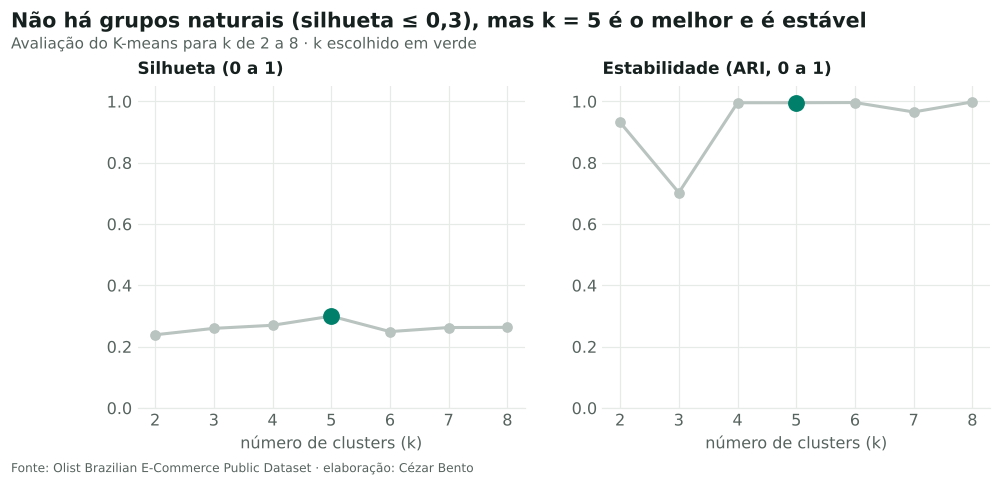

In [6]:
K = 5
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, col, titulo in [(axes[0], "silhueta", "Silhueta (0 a 1)"), (axes[1], "estabilidade", "Estabilidade (ARI, 0 a 1)")]:
    ax.plot(avaliacao.index, avaliacao[col], color=COR["contexto"], marker="o", lw=2)
    ax.plot(K, avaliacao.loc[K, col], marker="o", ms=10, color=COR["principal"])
    ax.set_ylim(0, 1.05); ax.set_title(titulo, fontsize=11, pad=8); ax.set_xlabel("número de clusters (k)")
fig.suptitle("Não há grupos naturais (silhueta ≤ 0,3), mas k = 5 é o melhor e é estável", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.06)
fig.text(0.01, 0.97, "Avaliação do K-means para k de 2 a 8 · k escolhido em verde",
         fontsize=10, color=COR["texto2"])
fonte(fig, FONTE)
fig.savefig("figuras/04_escolha_k.png")

**Leitura honesta:** a silhueta baixa em todo k mostra que os clientes formam um contínuo, não ilhas separadas. A segmentação, então, é uma **partição útil** para agir, não uma descoberta de tipos "reais". O critério passa a ser: o resultado é estável (a mesma partição aparece com outra semente) e cada grupo pede uma ação diferente? Com k = 5, sim.

In [7]:
km = KMeans(K, n_init=10, random_state=0).fit(Z)
clientes["cluster"] = km.labels_
medias = clientes.groupby("cluster")[VARIAVEIS].mean()
clientes["segmento"] = clientes["cluster"].map(nomear_clusters(medias))

perfil = clientes.groupby("segmento").agg(
    clientes=("valor", "size"), receita=("valor", "sum"), ticket=("ticket", "median"),
    parcelas=("parcelas", "mean"), frete_pct=("frete_pct", "median"), itens=("itens", "mean"), nota=("nota", "mean"))
perfil["% clientes"] = perfil.clientes / perfil.clientes.sum() * 100
perfil["% receita"] = perfil.receita / perfil.receita.sum() * 100
perfil = perfil.sort_values("% receita", ascending=False)
print(perfil.drop(columns=["clientes", "receita"]).round(2).to_string())

                            ticket  parcelas  frete_pct  itens  nota  % clientes  % receita
segmento                                                                                   
Compra padrão               125.23      1.98       0.14   1.06  4.70       42.32      42.10
Parcelado, ticket alto      222.98      8.03       0.11   1.10  4.32       14.84      31.78
Insatisfeitos               104.28      2.42       0.19   1.15  1.67       14.43      12.41
Ticket baixo, frete pesado   46.35      1.73       0.33   1.05  4.55       26.18       8.45
Cesta com vários itens      242.48      3.77       0.23   3.80  3.41        2.23       5.27


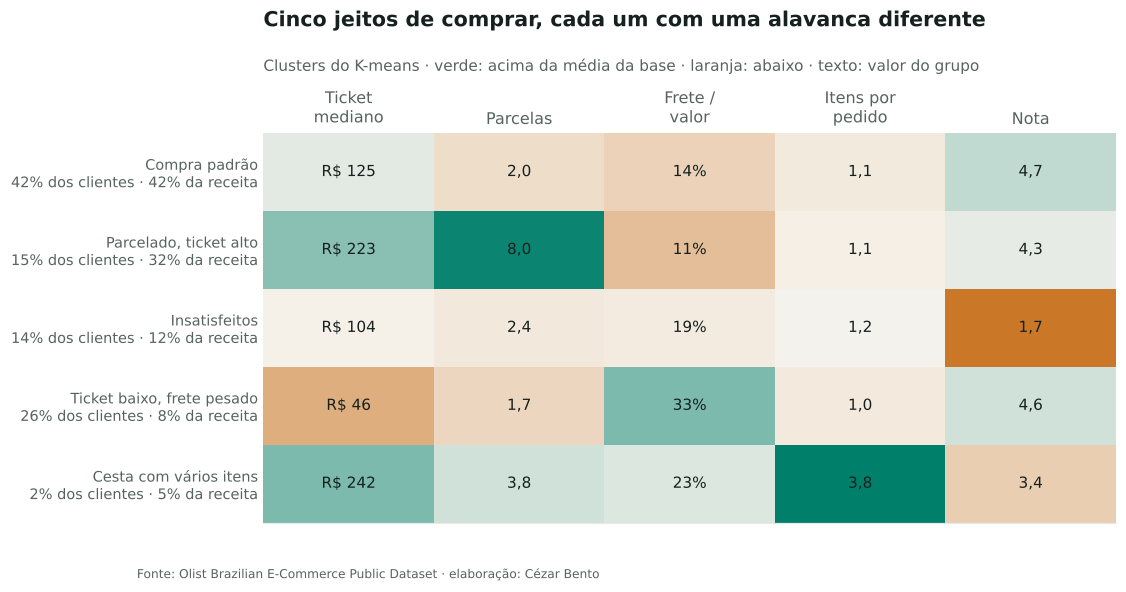

In [8]:
# Mapa de calor: cor = quanto o grupo se afasta da média da base (desvios-padrão),
# texto = valor real, para o gráfico ser lido sem tabela ao lado.
colunas = {"ticket": "Ticket\nmediano", "parcelas": "Parcelas", "frete_pct": "Frete /\nvalor",
           "itens": "Itens por\npedido", "nota": "Nota"}
media_base = clientes[["ticket", "parcelas", "frete_pct", "itens", "nota"]]
z = (perfil[list(colunas)] - media_base.mean()) / media_base.std()
z["ticket"] = (np.log(perfil["ticket"]) - np.log(clientes["ticket"]).mean()) / np.log(clientes["ticket"]).std()

fmt = {"ticket": lambda v: f"R$ {br(v)}", "parcelas": lambda v: br(v, 1), "frete_pct": lambda v: f"{br(v * 100)}%",
       "itens": lambda v: br(v, 1), "nota": lambda v: br(v, 1)}
fig, ax = plt.subplots(figsize=(10, 4.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", [COR["destaque"], "#F7F4EE", COR["principal"]])
ax.imshow(z.values.clip(-2, 2), cmap=cmap, vmin=-2, vmax=2, aspect="auto")
for (i, j), _ in np.ndenumerate(z.values):
    col = list(colunas)[j]
    ax.text(j, i, fmt[col](perfil.iloc[i][col]), ha="center", va="center", fontsize=10, color=COR["texto"])
ax.set_xticks(range(len(colunas)), colunas.values()); ax.xaxis.tick_top()
ax.set_yticks(range(len(perfil)), [f"{s}\n{br(c)}% dos clientes · {br(r)}% da receita"
                                   for s, c, r in zip(perfil.index, perfil["% clientes"], perfil["% receita"])], fontsize=9.5)
ax.grid(False)
ax.set_title("Cinco jeitos de comprar, cada um com uma alavanca diferente", pad=70)
ax.text(0, 1.16, "Clusters do K-means · verde: acima da média da base · laranja: abaixo · texto: valor do grupo",
        transform=ax.transAxes, fontsize=10, color=COR["texto2"])
fonte(fig, FONTE, y=0.02)
fig.savefig("figuras/05_perfis.png")

## 4. Quem volta?

Para medir recompra sem viés, só entram clientes cuja primeira compra aconteceu pelo menos 180 dias antes do fim da base. Assim todo mundo teve a mesma janela para voltar. As taxas são pequenas, então cada uma vem com intervalo de confiança de 95% (método de Wilson).

In [9]:
primeiras = primeira_compra(pedidos)
primeiras = primeiras.join(clientes["segmento"])
print(f"{br(len(primeiras))} clientes com janela completa · voltaram em até {JANELA_RECOMPRA} dias: "
      f"{br(primeiras.voltou.mean() * 100, 1)}% · mediana até voltar: {br(primeiras.dias_ate_voltar.median())} dias")

por_seg = primeiras.groupby("segmento").voltou.agg(["sum", "size"])
p, lo, hi = taxa_wilson(por_seg["sum"], por_seg["size"])
print((pd.DataFrame({"recompra %": p, "IC inf": lo, "IC sup": hi}, index=por_seg.index) * 100).round(2).to_string())

56.451 clientes com janela completa · voltaram em até 180 dias: 2,0% · mediana até voltar: 106 dias
                            recompra %  IC inf  IC sup
segmento                                              
Cesta com vários itens            2.82    2.04    3.90
Compra padrão                     2.21    2.03    2.41
Insatisfeitos                     1.54    1.30    1.83
Parcelado, ticket alto            2.40    2.10    2.74
Ticket baixo, frete pesado        1.51    1.33    1.73


                       taxa    lo    hi
Cool stuff             1.04  0.71  1.50
Games                  1.35  0.73  2.47
Malas                  1.41  0.77  2.58
Móveis de escritório   1.50  0.86  2.61
Automotivo             1.51  1.05  2.16
Informática            1.52  1.18  1.95
Papelaria              1.59  1.05  2.40
Utilidades domésticas  1.62  1.23  2.14
Eletrônicos            1.69  1.14  2.50
Brinquedos             1.73  1.30  2.30
Telefonia              1.75  1.32  2.33
Relógios e presentes   1.80  1.36  2.37
Bebês                  1.92  1.34  2.74
Beleza e saúde         1.96  1.59  2.41
Perfumaria             2.05  1.51  2.77
Ferramentas e jardim   2.15  1.64  2.83
Móveis e decoração     2.38  1.94  2.91
Esporte e lazer        2.62  2.19  3.12
Cama, mesa e banho     2.75  2.35  3.22
Pet shop               2.98  2.03  4.36
Bolsas e acessórios    3.44  2.54  4.65


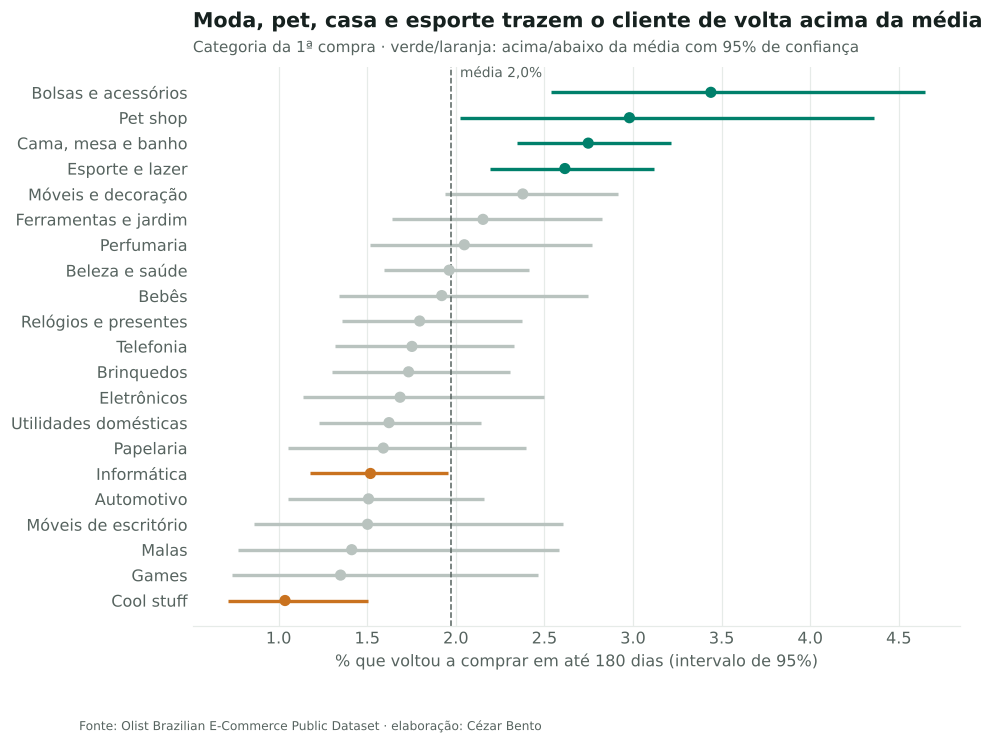

In [10]:
por_cat = primeiras[primeiras.categoria != "sem_categoria"].groupby("categoria").voltou.agg(["sum", "size"]).query("size >= 700")
p, lo, hi = taxa_wilson(por_cat["sum"], por_cat["size"])
cat = pd.DataFrame({"taxa": p, "lo": lo, "hi": hi, "n": por_cat["size"]}, index=por_cat.index).sort_values("taxa")
cat.index = [CATEGORIA_PT.get(c, c) for c in cat.index]
media = primeiras.voltou.mean()
print((cat[["taxa", "lo", "hi"]] * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 6.6))
y = np.arange(len(cat))
acima = cat["lo"] > media
abaixo = cat["hi"] < media
cores = [COR["principal"] if a else COR["destaque"] if b else COR["contexto"] for a, b in zip(acima, abaixo)]
ax.hlines(y, cat["lo"] * 100, cat["hi"] * 100, color=cores, lw=2.2)
ax.scatter(cat["taxa"] * 100, y, color=cores, s=40, zorder=3)
ax.axvline(media * 100, color=COR["texto2"], lw=1, ls="--")
ax.text(media * 100 + 0.05, len(cat) - 0.4, f"média {br(media * 100, 1)}%", fontsize=9, color=COR["texto2"])
ax.set_yticks(y, cat.index); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"% que voltou a comprar em até {JANELA_RECOMPRA} dias (intervalo de 95%)")
ax.set_title("Moda, pet, casa e esporte trazem o cliente de volta acima da média")
subtitulo(ax, "Categoria da 1ª compra · verde/laranja: acima/abaixo da média com 95% de confiança")
fonte(fig, FONTE)
fig.savefig("figuras/06_recompra_categoria.png")

**Leitura:**
- Por segmento, **insatisfeitos** e **ticket baixo, frete pesado** voltam cerca de um terço menos (1,5% contra 2,2% a 2,4%), e os intervalos não se sobrepõem. A experiência da primeira compra pesa na volta.
- Por categoria, a diferença chega a 3×: produtos de **reposição ou uso contínuo** (bolsas e acessórios, pet, cama-mesa-banho, esporte) ficam acima da média com 95% de confiança; informática e cool stuff ficam abaixo. Games, malas e móveis de escritório parecem baixos, mas a amostra não permite afirmar.

## 5. Dá para prever quem volta?

Se desse, uma campanha poderia mirar só os clientes com maior chance. O teste usa só o que se sabe na primeira compra (valor, parcelas, frete, itens, nota, atraso, prazo, categoria e estado), com divisão temporal: treino nas primeiras compras até set/2017, teste de out/2017 a fev/2018.

Treino: 25.668 · teste: 30.783 · AUC no teste: 0.566 · lift nos 10% do topo: 1.34


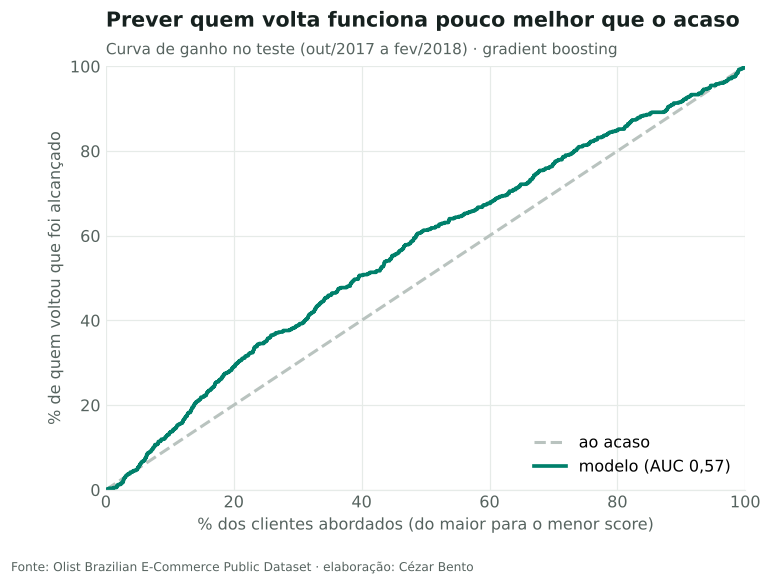

In [11]:
base = primeiras[["valor", "parcelas", "frete_pct", "itens", "nota", "atraso_dias", "dias_entrega"]].copy()
base["valor"] = np.log(base["valor"])
base = base.fillna(base.median())
top = primeiras.categoria.value_counts().index[:20]
Xp = base.join(pd.get_dummies(primeiras.categoria.where(primeiras.categoria.isin(top), "outra"), dtype=float)) \
         .join(pd.get_dummies(primeiras.estado, prefix="uf", dtype=float))
yp = primeiras.voltou.astype(int)
treino = primeiras.data < "2017-10-01"

modelo = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0)
modelo.fit(Xp[treino], yp[treino])
prob = modelo.predict_proba(Xp[~treino])[:, 1]
auc = roc_auc_score(yp[~treino], prob)

# Curva de ganho: abordando os x% com maior probabilidade, que fração de quem voltou é alcançada?
ordem = np.argsort(-prob)
alcancados = np.cumsum(yp[~treino].values[ordem]) / yp[~treino].sum()
fracao = np.arange(1, len(prob) + 1) / len(prob)
lift10 = alcancados[int(0.1 * len(prob)) - 1] / 0.1
print(f"Treino: {br(treino.sum())} · teste: {br((~treino).sum())} · AUC no teste: {auc:.3f} · lift nos 10% do topo: {lift10:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(fracao * 100, fracao * 100, color=COR["contexto"], lw=2, ls="--", label="ao acaso")
ax.plot(fracao * 100, alcancados * 100, color=COR["principal"], lw=2.4, label=f"modelo (AUC {br(auc, 2)})")
ax.set_xlabel("% dos clientes abordados (do maior para o menor score)")
ax.set_ylabel("% de quem voltou que foi alcançado"); ax.legend(loc="lower right")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title("Prever quem volta funciona pouco melhor que o acaso")
subtitulo(ax, "Curva de ganho no teste (out/2017 a fev/2018) · gradient boosting")
fonte(fig, FONTE)
fig.savefig("figuras/07_previsao_recompra.png")

**Leitura honesta:** com o que se sabe da primeira compra, o modelo mal supera o acaso. Isso é um resultado, não um fracasso: evita gastar com uma campanha de retenção "inteligente" que, na prática, seria aleatória. Para prever recompra seria preciso outro tipo de dado (navegação, e-mails abertos, carrinho abandonado), que a base pública não tem.

## 6. Recomendações

| Grupo | O que o dado mostra | Ação sugerida |
|---|---|---|
| **Ticket baixo, frete pesado** | O frete é um terço do valor pago; voltam um terço menos | Frete grátis acima de um valor mínimo, para aumentar o ticket e diluir o frete |
| **Parcelado, ticket alto** | Maior ticket da base, cerca de 8 parcelas | Ofertas de crédito e de produtos complementares no pós-venda |
| **Insatisfeitos** | Nota média abaixo de 2; voltam um terço menos | Recuperação pelo atendimento: o [projeto de NLP](../NLP_Avaliacoes) já faz a triagem dessas avaliações |
| **Cesta com vários itens** | Pedidos com 3+ itens e nota mais baixa | Investigar entregas parciais: itens de um mesmo pedido chegando separados |
| **Categorias de reposição** | Moda, pet, casa e esporte voltam acima da média | Concentrar a verba de recompra (lembretes, cupom de 2ª compra) nessas categorias |

**Como validar:** cada ação vira um teste A/B com grupo de controle. Com recompra base de ~2%, detectar um aumento para 2,5% exige cerca de 14 mil clientes por grupo (poder de 80%, 5% de significância).

## Limitações

- **Uma loja, dois anos:** a recompra baixa pode ser típica de marketplace com identificador de cliente por pedido; em outra base o RFM clássico funcionaria melhor.
- **Clusters sem estrutura natural:** os grupos são úteis para ação, mas as fronteiras são arbitrárias; um cliente perto da fronteira poderia cair no grupo vizinho.
- **Correlação, não causa:** pet shop retém mais porque o produto acaba, não necessariamente por algo que a Olist fez. Ações só se justificam depois de testadas.

In [12]:
# Conferência do tamanho de amostra citado nas recomendações (teste de duas proporções)
from scipy.stats import norm
p1, p2 = 0.02, 0.025
za, zb = norm.ppf(1 - 0.05 / 2), norm.ppf(0.8)
n = ((za * np.sqrt(2 * ((p1 + p2) / 2) * (1 - (p1 + p2) / 2)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / (p2 - p1) ** 2
print(f"Clientes por grupo: {br(n)}")

Clientes por grupo: 13.809
